# [Harness name]: [one-line headline finding]

**Commit SHA:** `<40-character output of git rev-parse HEAD>`
**Repo:** <GitHub URL> (Apache-2.0 / MIT)
**model_api in submission.yaml:** `google-cloud/<strongest model>`
**Judge used for dev scores:** `<frontier judge or JUDGE_MODEL name>`

> **How to use this notebook.** Every `TODO` is yours to fill with real numbers from `eval/run.py` runs.
> Figure cells fall back to clearly labelled PLACEHOLDER data so the notebook runs end to end. Replace it
> with `results/dev_runs.csv` before submitting. Delete these instruction blocks, then run the word-count
> cell at the bottom. The Writeup must stay under 2,000 words.

## Headline finding (put your single strongest result here)

TODO: two or three sentences for an ML researcher with no engineering background.
Template: *"On the 29 dev tasks, adding [X] raised the mean score from A to B on [model], at C% more tokens.
The dominant failure was [mode], not [what people expect]."*

| Model | Dev score | Mean cost / task | Notes |
|---|---|---|---|
| TODO | TODO | TODO | TODO |

<!-- not-in-writeup -->
## Step 0: run the dev eval, check artifacts, build `results/dev_runs.csv`

*Notebook-only section. Delete it before you paste anything into the Kaggle Writeup (the word count skips it).*

**Where this can run.** `eval/run.py` starts Docker containers, so this section works only in a notebook
whose kernel runs on a Linux or macOS machine with Docker, `uv` and Harbor installed (for example Jupyter on
your laptop or a cloud VM). Kaggle and Colab notebooks normally have no Docker daemon, so there you should run
the commands in a terminal elsewhere and only upload `results.json`. The preflight cell tells you which case
you are in.

**Cost and time.** A full run calls Google Cloud models billed to your project and can take hours, so every
step below is off until you set its flag to `True`. Try one task first with `TASKS`.

In [1]:
import subprocess, shutil, os, time, json
from pathlib import Path

# ---- switches: everything that spends money or time is off by default ----
RUN_EVAL = False            # start the dev run (billed to your Google Cloud project)
RUN_KIT_CHECK = False       # kit check: build, model, smoke tests, artifact review (needs Docker + model proxy)
RUN_ARTIFACT_GRADE = False  # regrade committed artifacts/ in Docker with the judge (needs judge settings)

# ---- paths and run settings: edit these ----
PLE_REPO = Path('~/ple').expanduser()          # your clone of google-research/ple
HARNESS  = Path('~/my-harness').expanduser()   # harness folder with submission.yaml, itself a git repo
ENV_FILE = PLE_REPO / 'local.env'              # MODEL_PROXY_URL/KEY, HF_TOKEN, JUDGE_*; keep it out of HARNESS
TASKS    = ''                                  # e.g. 'data-hall-mep-routing' to try one task; '' runs all 29
CONFIG   = 'baseline'                          # label for this run, used in the ablation and cost figures
MODEL    = 'google-cloud/<id>'                 # same as model_api in submission.yaml
# Dollars per million tokens for MODEL (look up the Google Cloud price); None leaves cost blank
PRICE = dict(input=None, cache=None, output=None)
PASS_THRESHOLD = 0.5                           # score below this counts as a failure in Figure 3
RUN_DIR = None                                 # set by the run cell; set by hand to reuse an old run

def sh(cmd, cwd=None, check=False):
    cwd = cwd or PLE_REPO
    print('$', ' '.join(map(str, cmd)))
    if not Path(cwd).exists():
        print('Skipped: folder not found:', cwd, '(set PLE_REPO to your clone of google-research/ple)')
        return subprocess.CompletedProcess(cmd, 127, '', '')
    if not Path(HARNESS).exists():
        print('Skipped: harness folder not found:', HARNESS, '(set HARNESS)')
        return subprocess.CompletedProcess(cmd, 127, '', '')
    if shutil.which(cmd[0]) is None:
        print('Skipped: command not installed:', cmd[0])
        return subprocess.CompletedProcess(cmd, 127, '', '')
    p = subprocess.run(cmd, cwd=cwd, text=True, capture_output=True)
    print((p.stdout or '')[-6000:])
    if p.stderr:
        print(p.stderr[-3000:])
    if check and p.returncode:
        raise RuntimeError(f'command exited with {p.returncode}')
    return p

def env_args():
    return ['--env-file', str(ENV_FILE)] if ENV_FILE.exists() else []

In [2]:
# Preflight: reports what is missing without failing
def docker_up():
    if not shutil.which('docker'):
        return False
    return subprocess.run(['docker', 'info'], capture_output=True).returncode == 0

def env_names():
    names = set(os.environ)
    if ENV_FILE.exists():
        for line in ENV_FILE.read_text().splitlines():
            line = line.strip()
            if line and not line.startswith('#') and '=' in line:
                names.add(line.split('=', 1)[0].replace('export ', '').strip())
    return names

have = env_names()
checks = {
    'Docker daemon running': docker_up(),
    'uv installed': bool(shutil.which('uv')),
    'harbor installed': bool(shutil.which('harbor')),
    'PLE repo cloned (eval/run.py)': (PLE_REPO / 'eval' / 'run.py').exists(),
    'harness has submission.yaml': (HARNESS / 'submission.yaml').exists(),
    'HF_TOKEN set': 'HF_TOKEN' in have,
    'MODEL_PROXY_URL set': 'MODEL_PROXY_URL' in have,
    'MODEL_PROXY_KEY set': 'MODEL_PROXY_KEY' in have,
}
for k, v in checks.items():
    print(('OK      ' if v else 'MISSING ') + k)
if not all(checks.values()):
    print('Fix the MISSING items before turning on any RUN_* switch.')

MISSING Docker daemon running
OK      uv installed
MISSING harbor installed
MISSING PLE repo cloned (eval/run.py)
MISSING harness has submission.yaml
MISSING HF_TOKEN set
MISSING MODEL_PROXY_URL set
MISSING MODEL_PROXY_KEY set
Fix the MISSING items before turning on any RUN_* switch.


In [3]:
# Start the dev run in the background. It survives a kernel restart; follow it with the next cell.
if RUN_EVAL:
    out = 'runs/' + CONFIG + '-' + time.strftime('%Y%m%d-%H%M%S')
    cmd = ['uv', 'run', 'python', 'eval/run.py', str(HARNESS), '--out', out] + env_args()
    if TASKS:
        cmd += ['--tasks', TASKS]
    LOG = PLE_REPO / 'eval_notebook.log'
    proc = subprocess.Popen(cmd, cwd=PLE_REPO, stdout=open(LOG, 'w'), stderr=subprocess.STDOUT,
                            start_new_session=True)
    RUN_DIR = PLE_REPO / out
    print('started:', ' '.join(cmd))
    print('log:', LOG, '| run folder:', RUN_DIR)
else:
    print('RUN_EVAL is False: nothing started.')

RUN_EVAL is False: nothing started.


In [4]:
# Progress: run this cell repeatedly. Safe if nothing is running.
LOG = PLE_REPO / 'eval_notebook.log'
state = 'no run started from this kernel'
if 'proc' in globals():
    state = 'still running' if proc.poll() is None else 'finished with exit code ' + str(proc.returncode)
print('status:', state)
if LOG.exists():
    print('\n'.join(LOG.read_text().splitlines()[-25:]))

status: no run started from this kernel


In [5]:
# Artifact checks. Commit first: kit artifacts also reads the working-tree git state.
#   git -C <harness> add -A && git -C <harness> commit -m "harness and dev artifacts"
sh(['uv', 'run', 'python', '-m', 'kit', 'artifacts', str(HARNESS)])
if RUN_KIT_CHECK:
    sh(['uv', 'run', 'python', '-m', 'kit', 'check', str(HARNESS)] + env_args())
if RUN_ARTIFACT_GRADE:
    sh(['uv', 'run', 'python', 'eval/run.py', '--artifacts', str(HARNESS)] + env_args())

$ uv run python -m kit artifacts /root/my-harness
Skipped: folder not found: /root/ple (set PLE_REPO to your clone of google-research/ple)


In [6]:
# Convert a finished run's results.json into results/dev_runs.csv (appends, so you can compare configs/models).
import pandas as pd

UNLABELED = 'unlabeled (needs manual label)'
DISCIPLINE = {}   # optional: {'task-id': 'mechanical', ...}; not recorded by eval/run.py, fill from the dataset page

def run_to_rows(run_dir):
    r = json.loads((Path(run_dir) / 'results.json').read_text())
    if not r.get('complete', False):
        print('warning: run is incomplete; unmeasured tasks:', r.get('unmeasured'))
    rows = []
    for t in r['tasks']:
        tok = t.get('tokens') or {}
        tin, tcache, tout = tok.get('input'), tok.get('cache'), tok.get('output')
        cost = None
        if all(v is not None for v in PRICE.values()) and None not in (tin, tcache, tout):
            cost = (tin * PRICE['input'] + tcache * PRICE['cache'] + tout * PRICE['output']) / 1e6
        score = t.get('score') or 0.0
        rows.append(dict(
            task_id=t['id'], discipline=DISCIPLINE.get(t['id'], 'unknown'),
            model=r.get('model', MODEL), config=CONFIG, score=score,
            input_tokens=tin, cache_tokens=tcache, output_tokens=tout, cost_usd=cost,
            runtime_s=t.get('seconds'), n_calls=None, n_verify_attempts=None,
            measured=t.get('measured'), status=t.get('status'),
            failure_mode='none' if score >= PASS_THRESHOLD else UNLABELED))
    return pd.DataFrame(rows)

run_dir = RUN_DIR
if run_dir is None:
    found = sorted((PLE_REPO / 'runs').glob(CONFIG + '-*')) if (PLE_REPO / 'runs').exists() else []
    run_dir = found[-1] if found else None
if run_dir is None or not (Path(run_dir) / 'results.json').exists():
    print('No results.json yet. Finish a run, or set RUN_DIR to a folder that has one.')
else:
    new = run_to_rows(run_dir)
    Path('results').mkdir(exist_ok=True)
    csv = Path('results/dev_runs.csv')
    old = pd.read_csv(csv) if csv.exists() else pd.DataFrame()
    both = pd.concat([old, new], ignore_index=True).drop_duplicates(['task_id', 'model', 'config'], keep='last')
    both.to_csv(csv, index=False)
    print('wrote', csv, 'with', len(both), 'rows; mean score of this run:', round(new.score.mean(), 3))
    print('Next: open the rows marked unlabeled and set failure_mode by hand (see FAILURE_MODES below).')

No results.json yet. Finish a run, or set RUN_DIR to a folder that has one.


In [7]:
import json, os, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

RESULTS = Path("results/dev_runs.csv")   # one row per (task, model, config) run
# Expected columns:
#   task_id, discipline, model, config, score, input_tokens, output_tokens,
#   cost_usd, runtime_s, n_calls, n_verify_attempts, failure_mode
# failure_mode is "none" for passes, otherwise one of FAILURE_MODES below.

FAILURE_MODES = [
    "misread drawing/callout",
    "wrong code clause/table",
    "unit/conversion error",
    "stopped early / missing deliverable",
    "tool/format error (IFC, xlsx, PDF)",
    "geometry/clash error",
    "arithmetic/solver error",
    "timeout/budget",
    "unlabeled (needs manual label)",
]

if RESULTS.exists():
    df = pd.read_csv(RESULTS)
    PLACEHOLDER = False
else:
    PLACEHOLDER = True
    rng = np.random.default_rng(0)
    rows = []
    for m in ["model-A", "model-B"]:
        for t in range(29):
            rows.append(dict(
                task_id=f"dev_{t:02d}",
                discipline=rng.choice(["structural", "civil", "electrical", "mechanical"]),
                model=m, config="final", score=float(rng.uniform(0, 1)),
                input_tokens=int(rng.integers(2e5, 3e6)), output_tokens=int(rng.integers(2e4, 3e5)),
                cost_usd=float(rng.uniform(0.2, 6)), runtime_s=float(rng.uniform(300, 9000)),
                n_calls=int(rng.integers(20, 300)), n_verify_attempts=int(rng.integers(0, 4)),
                failure_mode=str(rng.choice(["none"] + FAILURE_MODES))))
    df = pd.DataFrame(rows)

TAG = "PLACEHOLDER DATA - replace with real runs" if PLACEHOLDER else ""
print("Loaded", len(df), "rows;", "PLACEHOLDER" if PLACEHOLDER else "real data")

Loaded 58 rows; PLACEHOLDER


## 1. Insight and failure analysis (25 pts)

**The non-obvious lesson.** TODO: one claim a reader would not have guessed (for example "most failures were
not wrong physics but a missing deliverable the agent never noticed it owed").

### Controlled ablations
Each row changes one thing on the same 29 dev tasks and the same model.

| Change | Score before | Score after | Token cost change | Verdict |
|---|---|---|---|---|
| Add deliverable-checklist gate before `done` | TODO | TODO | TODO | TODO |
| Add unit-audit pass over every calculation | TODO | TODO | TODO | TODO |
| Re-read cited code table before using a value | TODO | TODO | TODO | TODO |
| Rasterize drawing sheets, read callouts visually | TODO | TODO | TODO | TODO |
| Context compaction every N turns | TODO | TODO | TODO | TODO |

### Ideas that failed
TODO: two or three things you tried that did not help, with a one-line reason each. Judges reward these.

### Where the dev tasks fail
Figure 3 (below) breaks the failures down by mode. TODO: describe the top one or two with a concrete example
(task id, what the agent read or computed, what the correct value was).

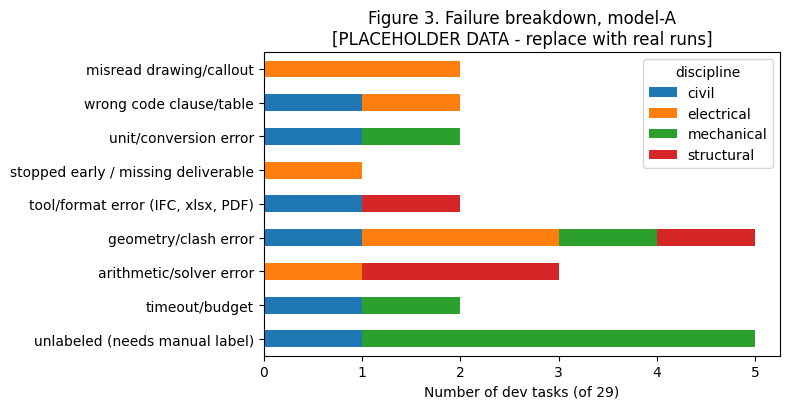

In [8]:
# FIGURE 3: failure breakdown on the 29 dev tasks (final config, strongest model)
MODEL = df["model"].iloc[0] if PLACEHOLDER else df.groupby("model")["score"].mean().idxmax()
sub = df[(df.model == MODEL)]
if "config" in sub and (sub.config == "final").any():
    sub = sub[sub.config == "final"]
fails = sub[sub.failure_mode != "none"]
counts = fails.failure_mode.value_counts().reindex(FAILURE_MODES).fillna(0)
by_disc = fails.pivot_table(index="failure_mode", columns="discipline", values="task_id",
                            aggfunc="count").reindex(FAILURE_MODES).fillna(0)

fig, ax = plt.subplots(figsize=(8, 4.2))
by_disc.plot(kind="barh", stacked=True, ax=ax)
ax.invert_yaxis()
ax.set_xlabel("Number of dev tasks (of 29)")
ax.set_ylabel("")
ax.set_title(f"Figure 3. Failure breakdown, {MODEL}" + (f"\n[{TAG}]" if TAG else ""))
plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/fig3_failures.png", dpi=200)
plt.show()

## 2. Engineering reasoning: one task, agent vs. licensed engineer (25 pts)

Pick one dev task that exercises a real skill (reading drawings, code tables, running a solver).

**Task:** TODO task id and one-sentence plain-language description (for example "size a spread footing on
clay and report settlement").

| Step | Licensed engineer's workflow | Our agent's trajectory | Held up? |
|---|---|---|---|
| 1. Gather inputs | TODO (read boring logs, loads, site constraints) | TODO | TODO |
| 2. Pick governing code/clause | TODO | TODO | TODO |
| 3. Calculate | TODO (with units tracked) | TODO | TODO |
| 4. Check against limits | TODO | TODO | TODO |
| 5. Produce stamped-quality deliverable | TODO | TODO | TODO |

**Where the agent took a shortcut:** TODO.
**Skills that separated passes from failures:** TODO (for example PDF and CAD callout reading, table lookup
fidelity, solver use, IFC validity checking).
**Jargon note for ML readers:** TODO. Define any term (IFC4, shear wall, settlement memo) in one clause on
first use.

## 3. Cross-model generalizability (15 pts)

All runs on the 29 public dev tasks. Use at least two sponsored models, ideally from different families.

In [9]:
# Comparison table: score and cost per model (final config)
final = df[df.config == "final"] if (df.config == "final").any() else df
tbl = (final.groupby("model")
       .agg(mean_score=("score", "mean"),
            mean_cost_usd=("cost_usd", "mean"),
            mean_tokens=("input_tokens", lambda s: s.mean()),
            mean_runtime_min=("runtime_s", lambda s: s.mean() / 60),
            tasks=("task_id", "nunique"))
       .round(3).sort_values("mean_score", ascending=False))
if PLACEHOLDER:
    print("*** PLACEHOLDER DATA ***")
tbl

*** PLACEHOLDER DATA ***


,mean_score,mean_cost_usd,mean_tokens,mean_runtime_min,tasks
model,,,,,
model-A,0.562,3.159,1746857.276,85.518,29
model-B,0.545,3.199,1940271.414,78.572,29


**What helped every model:** TODO.
**What helped only one model (and why you think so):** TODO.
**How model choice shifts accuracy vs. token cost:** TODO.
**Model committed in `submission.yaml`:** TODO, with the one-sentence reason (score, cost, or Pareto position).

## 4. Efficiency and scaling (20 pts)

Stage 2 ranks on the score-vs-cost Pareto frontier, so show where extra compute stops paying.

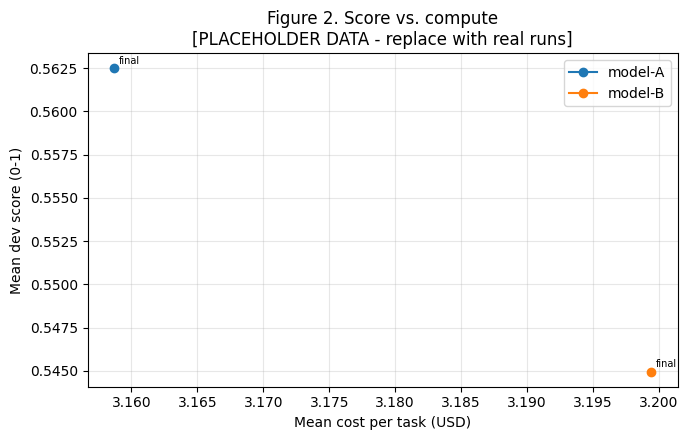

In [10]:
# FIGURE 2: score vs. compute. Use whichever x-axis you varied:
# cost_usd, input_tokens, n_calls, runtime_s, or n_verify_attempts.
if df["cost_usd"].notna().any():
    XCOL, XLABEL = "cost_usd", "Mean cost per task (USD)"
else:   # eval/run.py records tokens, not dollars; set PRICE in Step 0 to get cost
    XCOL, XLABEL = "input_tokens", "Mean input tokens per task"

g = (df.groupby(["model", "config"])
       .agg(score=("score", "mean"), x=(XCOL, "mean")).reset_index())

fig, ax = plt.subplots(figsize=(7, 4.5))
for m, d in g.groupby("model"):
    d = d.sort_values("x")
    ax.plot(d.x, d.score, marker="o", label=m)
    for _, r in d.iterrows():
        ax.annotate(r.config, (r.x, r.score), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(XLABEL)
ax.set_ylabel("Mean dev score (0-1)")
ax.set_title("Figure 2. Score vs. compute" + (f"\n[{TAG}]" if TAG else ""))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig2_score_vs_cost.png", dpi=200)
plt.show()

**Where accuracy plateaus:** TODO (for example "no gain beyond 2 verification attempts").
**Estimated remaining headroom:** TODO, with your reasoning (for example share of failures that are
unrecoverable by more compute, such as misread drawings, vs. recoverable, such as stopping early).
**Stage 2 safety margin:** TODO. Note typical per-task runtime vs. the 6-hour limit, and what the harness
does as the budget runs out (it must still emit `done`; a timeout scores 0.0).

## 5. Architecture and clarity (15 pts)

Figure 1 shows the harness. TODO: three to five sentences on the design for a non-engineer, with the headline
finding already stated at the top.

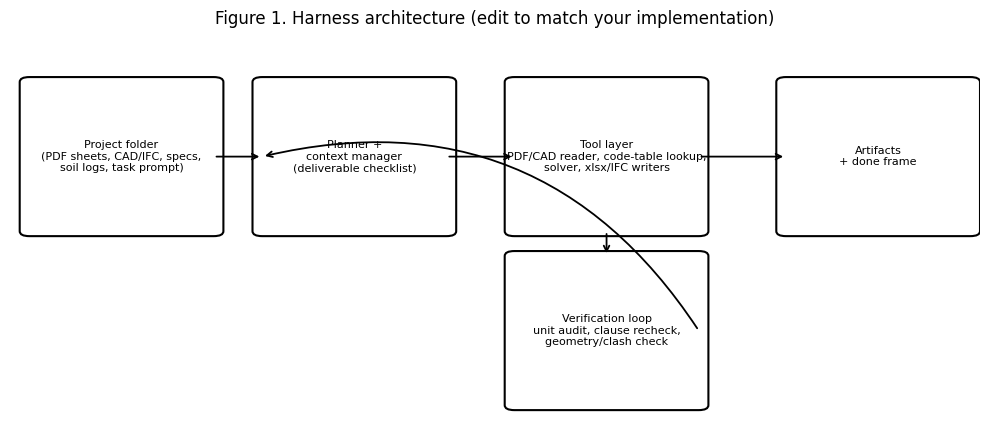

In [11]:
# FIGURE 1: architecture diagram. Edit the labels to match your actual harness.
boxes = {
    "Project folder\n(PDF sheets, CAD/IFC, specs,\nsoil logs, task prompt)": (0.02, 0.40),
    "Planner +\ncontext manager\n(deliverable checklist)": (0.26, 0.40),
    "Tool layer\nPDF/CAD reader, code-table lookup,\nsolver, xlsx/IFC writers": (0.52, 0.40),
    "Verification loop\nunit audit, clause recheck,\ngeometry/clash check": (0.52, 0.05),
    "Artifacts\n+ done frame": (0.80, 0.40),
}
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axis("off")
centers = {}
for label, (x, y) in boxes.items():
    w, h = 0.19, 0.30
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.01", fill=False, lw=1.5))
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", fontsize=8)
    centers[label] = (x, y, w, h)

keys = list(boxes)
def arrow(a, b, rad=0.0):
    xa, ya, wa, ha = centers[a]; xb, yb, wb, hb = centers[b]
    if abs(xa - xb) < 1e-6:   # vertical
        p0 = (xa + wa / 2, ya + (0 if yb < ya else ha)); p1 = (xb + wb / 2, yb + (hb if yb < ya else 0))
    else:
        p0 = (xa + wa, ya + ha / 2); p1 = (xb, yb + hb / 2)
    ax.annotate("", xy=p1, xytext=p0,
                arrowprops=dict(arrowstyle="->", lw=1.3, connectionstyle=f"arc3,rad={rad}"))

arrow(keys[0], keys[1]); arrow(keys[1], keys[2]); arrow(keys[2], keys[4])
arrow(keys[2], keys[3], 0.0); arrow(keys[3], keys[1], 0.35)
ax.set_xlim(0, 1); ax.set_ylim(0, 0.8)
ax.set_title("Figure 1. Harness architecture (edit to match your implementation)")
plt.tight_layout()
plt.savefig("figures/fig1_architecture.png", dpi=200)
plt.show()

## Reproducibility and judge disclosure

- Dev artifacts generated with `uv run python eval/run.py`; `artifacts/manifest.json` hash matches.
- `uv run python -m kit check` and `uv run python -m kit artifacts` both pass at the commit above.
- Local judge used for dev scoring: TODO (name the model if it is not a frontier judge). Organizers re-score
  with the official judge, so expect some shift.
- No dev answers are hard-coded.

In [12]:
# Word-count check for the final Writeup (markdown only; excludes code cells).
import json, glob
# Find this notebook without relying on its file name; works if you renamed it.
candidates = [p for p in glob.glob("*.ipynb") + glob.glob("../*.ipynb") + glob.glob("/kaggle/working/*.ipynb")
              if "writeup" in p.lower() or "ple" in p.lower()] or glob.glob("*.ipynb")
if not candidates:
    print("Could not find the .ipynb file from here (Kaggle and Colab often hide it).")
    print("Download the notebook, then run: python -c \"import json,re,sys;"
          "nb=json.load(open(sys.argv[1]));t=' '.join(''.join(c['source']) for c in nb['cells'] "
          "if c['cell_type']=='markdown');print(len(re.sub(r'[|>*#`-]',' ',t).split()))\" YOUR_FILE.ipynb")
else:
    nb = json.load(open(candidates[0]))
    text = "\n".join("".join(c["source"]) for c in nb["cells"]
                      if c["cell_type"] == "markdown" and "not-in-writeup" not in "".join(c["source"]))
    text = re.sub(r"[|>*#`-]", " ", text)
    print(f"{candidates[0]}: approx. {len(text.split())} words (limit 2000; delete instruction text first)")

__notebook__.ipynb: approx. 752 words (limit 2000; delete instruction text first)
